# Lab08 - Bài tập

### Bài 1

Nghiên cứu mức thu nhập ($X$) và chi tiêu ($Y$) trong một tháng của một công ty. Khảo sát ngẫu nhiên 7 nhân viên, ta thu được bảng số liệu sau:

| X            | 130     | 150      | 133      | 170      | 170      | 210      | 230      |
| :----------: | :-----: | :------: | :------: | :------: | :------: | :------: | :------: |
| **Y**        | **84**  | **120**  | **108**  | **130**  | **130**  | **150**  | **160**  |


a. Dựa vào bảng dữ liệu trên cho biết có xây dựng được mô hình hồi quy hay không? Nếu có hãy xây dựng mô hình hồi quy để ước tính chi tiêu dựa theo thu nhập

b. Dự đoán mức chi tiêu của nhân viên công ty trên nếu biết thu nhập là 200$

In [1]:
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
# Thu nhập (X)
x = np.array([130, 150, 133, 170, 170, 210, 230])

# Chi tiêu (Y)
y = np.array([84, 120, 108, 130, 130, 150, 160])

In [3]:
np.corrcoef(x, y)

array([[1.        , 0.94705241],
       [0.94705241, 1.        ]])

Vì hệ số tương quan dương và gần 1 nên X và Y có tương quan tuyến tính thuận khá mạnh. Có thể xây dựng mô hình hồi quy tuyến tính.

In [4]:
tu = sum((x - x.mean()) * (y - y.mean()))
tu

5466.0

In [5]:
mau = sum((x - x.mean()) * (x - x.mean()))
mau

8567.714285714286

In [6]:
b1 = tu / mau
b1

0.6379764564644679

In [7]:
b0 = y.mean() - b1 * x.mean()
b0

17.270583919698552

In [8]:
print(f"Mô hình hồi quy: y = {b0.round(4)} + {b1.round(4)}x")

Mô hình hồi quy: y = 17.2706 + 0.638x


In [9]:
y_du_doan = b0 + b1 * x

tu = sum((y - y_du_doan)**2)
mau = sum((y - y.mean())**2)

R2 = 1 - tu/mau

print('Hệ số xác định mô hình: ', R2)

Hệ số xác định mô hình:  0.8969082590110037


Mô hình giải thích được khoảng 86,49% sự biến thiên của chi tiêu trong bộ dữ liệu. Đây là mức giải thích tương đối tốt.

In [10]:
# b. Dự đoán mức chi tiêu của nhân viên công ty trên nếu biết thu nhập là 200$

print('Chi tiêu: ', 42.5284 + 0.5319 * 200)

Chi tiêu:  148.9084


Vậy chi tiêu dự đoán là khoảng 148,91 .

### Bài 2

Tiến hành nghiên cứu mối quan hệ giữa:

- X: giá bán kẻ của thịt gà (nghìn/kg) 
- Y: lượng thịt gà tiêu thụ (kg/tháng)

Dữ liệu thu được gồm 10 tháng như sau:

| X            | 35       | 40       | 45       | 40       | 38       | 40       | 45       | 30       | 42       | 38       |
| :----------: | :------: | :------: | :------: | :------: | :------: | :------: | :------: | :------: | :------: | :------: |
| **Y**        | **2.29** | **2.04** | **0.59** | **2.06** | **2.50** | **2.32** | **1.57** | **3.96** | **1.43** | **2.34** |


a. Dựa vào bảng dữ liệu trên cho biết có xây dựng được mô hình hồi quy hay không? Nếu có hãy xây dựng mô hình hồi quy để ước tính lượng tiêu thụ thịt gà theo giá bán.

b. Dự đoán lượng tiêu thụ khi giá bán lẻ là 41(kg/tháng)

In [19]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([35, 40, 45, 40, 38, 40, 45, 30, 42, 38])
y = np.array([2.29, 2.04, 0.59, 2.06, 2.50, 2.32, 1.57, 3.96, 1.43, 2.34])

In [20]:
np.corrcoef(x, y)

array([[ 1.        , -0.91953287],
       [-0.91953287,  1.        ]])

giá bán và lượng tiêu thụ có tương quan tuyến tính nghịch khá mạnh. Có thể xây dựng mô hình hồi quy tuyến tính.

In [21]:
import statsmodels.api as sm
import pandas as pd

In [22]:
model = sm.formula.ols(
    'y~x',
    data=pd.DataFrame({'x': x, 'y': y})
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.846
Model:                            OLS   Adj. R-squared:                  0.826
Method:                 Least Squares   F-statistic:                     43.79
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           0.000166
Time:                        10:06:15   Log-Likelihood:                -2.9041
No. Observations:                  10   AIC:                             9.808
Df Residuals:                       8   BIC:                             10.41
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.0808      1.060      8.570      0.0

C:\ProgramData\Anaconda3\lib\site-packages\scipy\stats\stats.py:1603: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=10
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


In [23]:
model.params

Intercept    9.080840
x           -0.177375
dtype: float64

In [24]:
print(f"Mô hình hồi quy: y = {model.params[0].round(4)} + {model.params[1].round(4)}x")

Mô hình hồi quy: y = 9.0808 + -0.1774x


In [25]:
print('Hệ số xác định mô hình: ', model.rsquared)

Hệ số xác định mô hình:  0.8455407062174737


mô hình giải thích được khoảng 84,55% sự biến thiên của lượng tiêu thụ trong dữ liệu.

In [26]:
model.predict(exog=dict(x=41))

0    1.808462
dtype: float64

## Bài 3

Dụa trên file dữ liệu `Advertising.csv` bạn hãy dự đoán doanh số bán hàng (`sales`) dựa trên số tiền chi cho các nền tảng tiếp thị khác nhau như `TV`, `Radio` và `Newspaper`

a. Đọc file dữ liệu cho biết các thông tin cơ bản về dữ liệu: kích thước, dữ liệu có giá trị trống hay không, hiện các giá trị thống kê cơ bản của các thuộc tính.

b. Để dự đoán doanh số bằng phương pháp hồi quy tuyến tính đơn giản (Simple Linear Regression) trước tiên cần lựa chọn một trong các thuộc tính còn lại. Theo bạn thuộc tính nào phù hợp để xây dựng mô hình hồi quy. Giải thích và minh họa bằng 2 cách

c. Xây dụng phương trình hồi quy, trực quan mô hình (đường thẳng) tìm được. Theo bạn để đánh giá mô hình trên cần dùng đại lượng nào?

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Advertising.csv')

In [28]:
df.head()

,ID,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [29]:
df.shape

(200, 5)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         200 non-null    int64  
 1   TV         200 non-null    float64
 2   Radio      200 non-null    float64
 3   Newspaper  200 non-null    float64
 4   Sales      200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [31]:
df.isnull().sum()

ID           0
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [32]:
df.describe()

,ID,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


---

In [33]:
# Cách 1: 

print('Tương quan TV và Sales:')
print(np.corrcoef(df['TV'], df['Sales']))

print('Tương quan Radio và Sales:')
print(np.corrcoef(df['Radio'], df['Sales']))

print('Tương quan Newspaper và Sales:')
print(np.corrcoef(df['Newspaper'], df['Sales']))

Tương quan TV và Sales:
[[1.         0.78222442]
 [0.78222442 1.        ]]
Tương quan Radio và Sales:
[[1.         0.57622257]
 [0.57622257 1.        ]]
Tương quan Newspaper và Sales:
[[1.         0.22829903]
 [0.22829903 1.        ]]


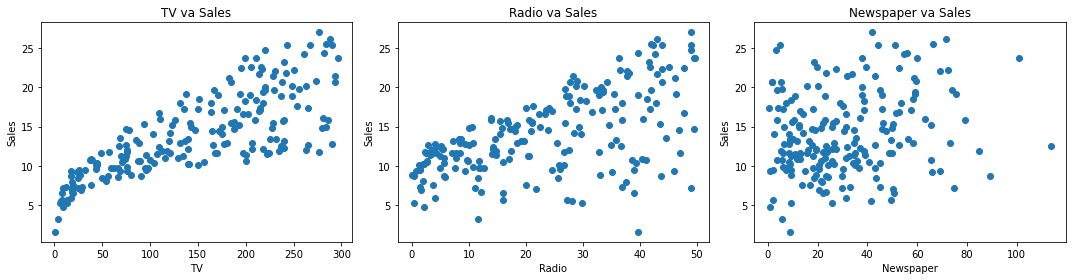

In [43]:
# Cách 2: 

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(df['TV'], df['Sales'])
plt.xlabel('TV')
plt.ylabel('Sales')
plt.title('TV va Sales')

plt.subplot(1, 3, 2)
plt.scatter(df['Radio'], df['Sales'])
plt.xlabel('Radio')
plt.ylabel('Sales')
plt.title('Radio va Sales')

plt.subplot(1, 3, 3)
plt.scatter(df['Newspaper'], df['Sales'])
plt.xlabel('Newspaper')
plt.ylabel('Sales')
plt.title('Newspaper va Sales')

plt.tight_layout()
plt.show()

TV là thuộc tính phù hợp nhất trong ba lựa chọn để xây dựng mô hình hồi quy tuyến tính đơn giản dự đoán Sales.

In [35]:
import statsmodels.api as sm

model = sm.formula.ols(
    'Sales ~ TV',
    data=df
).fit()

print(model.params)

Intercept    7.032594
TV           0.047537
dtype: float64


In [36]:
b0 = model.params['Intercept']
b1 = model.params['TV']

print(f'Mô hình hồi quy: Sales = {b0:.4f} + {b1:.4f}*TV')

Mô hình hồi quy: Sales = 7.0326 + 0.0475*TV


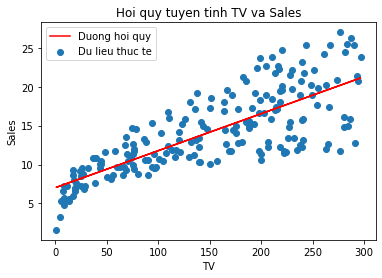

In [45]:
plt.scatter(df['TV'], df['Sales'], label='Du lieu thuc te')

plt.plot(
    df['TV'],
    model.predict(df),
    color='red',
    label='Duong hoi quy'
)

plt.xlabel('TV')
plt.ylabel('Sales')
plt.title('Hoi quy tuyen tinh TV va Sales')
plt.legend()
plt.show()

In [40]:
print('Hệ số xác định R²:', model.rsquared)

Hệ số xác định R²: 0.611875050850071
